In [1]:
#@title imports
import torch

import triton
import triton.language as tl

In [2]:
#@title RMSNorm kernels
# Kernel list:
# RMSNorm_fwd_kernel
# RMSNorm_bwd_dx_kernel
# RMSNorm_bwd_dw_kernel

@triton.jit
def RMSNorm_fwd_kernel(
    x_ptr, # inputs
    y_ptr, # write outputs here
    weight_ptr, # weights
    rstd_ptr, # write RMS here; should have shape (M, )
    M, N, # dimension of x (input) matrix (M rows, N columns)
    M_stride, # to move down a row, the stride
    eps, # added to avoid division by 0 / numerical stability
    BLOCK_SIZE: tl.constexpr, # next power of 2 after N, probably
):
  pid = tl.program_id(0)
  num_programs = tl.num_programs(0)
  col_offsets = tl.arange(0, BLOCK_SIZE)
  weights = tl.load(weight_ptr+col_offsets, mask=col_offsets<N, other=0.0)
  # Each program operates on one row at a time, based on program_id + k * num_programs in a for loop
  # Note: BLOCK_SIZE must be able to load the whole row at once
  for row in range(pid, M, num_programs):
    # In the for loop:
    # Calculate row offsets
    row_offsets = row * M_stride
    # Load the data, masking out-of-bounds indices
    x = tl.load(x_ptr+col_offsets+row_offsets, mask=col_offsets<N, other=0.0).to(tl.float32)
    # first, find the RMS of each row. Don't forget to add eps to RMS before sqrt for stability
    rms = tl.sqrt(((x*x).sum(0))/N+eps)
    rstd = 1/rms
    # multiply to get y
    y = rstd * x * weights
    # write the result to output (y_ptr), and write the rstd to rstd_ptr
    tl.store(y_ptr+col_offsets+row_offsets, y, mask=col_offsets<N)
    tl.store(rstd_ptr+row, rstd)

@triton.jit
def RMSNorm_bwd_dx_kernel(
    x_ptr, # original inputs
    weight_ptr, # weights
    dout_ptr, # the gradients we receive from a layer after us
    rstd_ptr, # pass in rstd calculated during fwd pass; but technically this is not necessary, and you could recompute it
    M, N, # dimension of the original x (input) matrix
    dx_ptr, # write the input gradients to here
    lock_ptr, # A vector, used for checking availability before atomic operations; initialized as all 0's
    dw_buffers_ptr, # ptrs are written here using atomic operations before being added to write to dw_ptr
    # ^^ Should be of shape (GROUP_SIZE, N); GROUP_SIZE is added below as a constexpr
    x_stride, # to move down a row in x (input) matrix
    buffer_stride, # to move down a row in the buffer matrix
    dout_stride, # to move down a row in dout matrix
    dx_stride, # to move down a row in dx
    BLOCK_SIZE: tl.constexpr, # next power of 2 after N, probably
    GROUP_SIZE: tl.constexpr, # used in atomic operations
):
  # Each program operates on one row at a time, based on program_id + k * num_programs in a for loop

  # The weight gradients must be summed up, so use a lock and count mechanism
  # The input gradients must be preserved separately (no summing) and written to dx_ptr

  pid = tl.program_id(0)
  num_programs = tl.num_programs(0)
  col_offsets = tl.arange(0, BLOCK_SIZE)
  # load weights outside because same weights are used for all inputs
  weight = tl.load(weight_ptr+col_offsets, mask=col_offsets<N, other=0.0).to(tl.float32)
  # dw_acc to use in the for loop; use float32 to keep precision
  dw_acc = tl.zeros((BLOCK_SIZE,), tl.float32)
  for row in range(pid, M, num_programs):
    # In the for loop:
    # Part 1: Calculate dx
    # First load the needed components, with masking if needed: x, rstd, weight, dout.
    x = tl.load(x_ptr+col_offsets+x_stride*row, mask=col_offsets<N, other=0.0).to(tl.float32)
    rstd = tl.load(rstd_ptr+row)
    dout = tl.load(dout_ptr+col_offsets+dout_stride*row, mask=col_offsets<N, other=0.0).to(tl.float32)
    # The formula is:
    # dx = rstd * (wdy - x_hat * c1), where:
    # wdy = weight * dout (element-wise multiplication)
    wdy = weight*dout
    # x_hat is the inputs, pre-transformation (so, x_hat = x * rstd)
    x_hat = x*rstd
    # c1 = (x_hat * wdy)'s mean
    c1 = (x_hat * wdy).sum(axis=-1) / N
    # Write to dx_ptr
    dx = rstd * (wdy - x_hat * c1)
    tl.store(dx_ptr+col_offsets+dx_stride*row, dx, mask=col_offsets<N)

    # Part 2: Update dw_acc
    # The formula is:
    # dw = dout * x_hat
    dw_acc += dout*x_hat

  # Part 3: add dw_acc to dw_buffers (which has shape (GROUP_SIZE, N))
  # The index of the buffer we write to is program_id % GROUP_SIZE.
  # We check whether that is available through a Lock tensor, with size 2 * GROUP_SIZE;
  # The first GROUP_SIZE is for availability, and the second GROUP_SIZE is for whether there's a value there,
  # so do we need to accumulate then write, or do we just write directly.
  # Note: write to dw_buffers first, not dw.
  buffer_id = pid % GROUP_SIZE
  lock = lock_ptr + buffer_id
  count = lock + GROUP_SIZE
  while tl.atomic_cas(lock, 0, 1) == 1:
    pass
  accumulate = tl.load(count)
  if accumulate == 0:
    tl.atomic_xchg(count, 1)
  else:
    dw_acc += tl.load(dw_buffers_ptr+col_offsets+buffer_id*buffer_stride, mask=col_offsets<N, other=0.0)
  tl.store(dw_buffers_ptr+col_offsets+buffer_id*buffer_stride, dw_acc, mask=col_offsets<N)
  # release lock
  tl.debug_barrier()
  tl.atomic_xchg(lock, 0)

@triton.jit
def RMSNorm_bwd_dw_kernel(
    dw_buffers_ptr, # has shape (GROUP_SIZE, N)
    dw_ptr, # has shape (N,)
    M, N, # dimensions of dw_buffers_ptr (M=GROUP_SIZE, N=N)
    M_stride, # to move down a row in buffers
    M_BLOCK_SIZE: tl.constexpr,
    N_BLOCK_SIZE: tl.constexpr,
):
  pid = tl.program_id(0)
  # First determine which N_BLOCK_SIZE columns the program should sum, using tl.program_id
  col_offsets = tl.arange(0, N_BLOCK_SIZE) + N_BLOCK_SIZE * pid
  row_offsets = tl.arange(0, M_BLOCK_SIZE)
  # The for loop should add together the columns from dw_buffers in an accumulator
  # Let it iterate over M_BLOCK_SIZE x N_BLOCK_SIZE tile, plus downward by M_BLOCK_SIZE rows
  # So it'd be taking from range(0, M, M_BLOCK_SIZE) * M_stride
  acc = tl.zeros((M_BLOCK_SIZE, N_BLOCK_SIZE), tl.float32) # float32 for precision
  for _ in range(0, M, M_BLOCK_SIZE):
    # In the for loop:
    # 1. Load the corresponding tile from dw_buffers, with mask = 0.0 if needed, and add to accumulator
    acc += tl.load(dw_buffers_ptr+col_offsets[None, :]+row_offsets[:, None]*M_stride, mask = (col_offsets[None, :] < N) & (row_offsets[:, None] < M), other = 0.0)
    # 2. update row_offsets for next iteration
    row_offsets += M_BLOCK_SIZE
  # Use .sum(axis=0) on the accumulator to get the final sum
  acc=acc.sum(axis=0)
  # Write the result to the corresponding columns of dw (which is a vector)
  tl.store(dw_ptr+col_offsets, acc, mask=col_offsets<N)

In [3]:
#@title RMSNorm function
class RMSNorm(torch.autograd.Function):
  @staticmethod
  def forward(ctx, x, weight, eps):
    # make contiguous
    x = x.contiguous()
    weight = weight.contiguous()

    # store x's shape (which should be 2D)
    M, N = x.shape

    # allocate tensors
    y = torch.empty_like(x)
    rstd = torch.empty((M, ), dtype=torch.float32, device = x.device)

    # choose block size
    if(N > 8192): # probably can allow a higher BLOCK_SIZE, but that may cause it to be slow
      raise RuntimeError("Decrease row length!")
    BLOCK_SIZE = triton.next_power_of_2(N)

    # choose num_warps and num_programs
    num_warps = min(max(BLOCK_SIZE // 256, 1), 8)
    # ^^ choose default
    num_programs = 1024

    # run forward kernel
    RMSNorm_fwd_kernel[(num_programs, )](
        x, y, weight, rstd, M, N,
        x.stride(0), eps, BLOCK_SIZE,
        num_warps = num_warps
    )

    # save for backward the needed variables
    ctx.save_for_backward(x, weight, rstd)
    ctx.BLOCK_SIZE = BLOCK_SIZE
    ctx.num_warps = num_warps
    # save BLOCK_SIZE and num_warps to reuse on backward pass
    # for simplicity, but it is probably not optimal to make them the same.
    return y

  @staticmethod
  def backward(ctx, dout):
    # make contiguous
    dout = dout.contiguous()

    # get saved numbers from forward pass
    x, weight, rstd = ctx.saved_tensors
    M, N = x.shape
    # choose group size
    GROUP_SIZE = 64

    # allocate tensors
    dx = torch.empty_like(x)
    lock = torch.zeros((2*GROUP_SIZE, ), dtype=torch.int32, device=x.device)
    dw_buffers = torch.zeros((GROUP_SIZE, N), dtype=torch.float32, device=x.device)
    dw = torch.empty((N, ), dtype = weight.dtype, device = x.device)
    # .empty is slightly faster than .zeros because it doesn't fill in the values,
    # it just leaves the leftover data already in the memory as is

    # run dx_kernel
    num_SMs = torch.cuda.get_device_properties(x.device).multi_processor_count
    RMSNorm_bwd_dx_kernel[(min(M, num_SMs * 4), )](
        x, weight, dout, rstd, M, N, dx, lock, dw_buffers,
        x.stride(0), dw_buffers.stride(0), dout.stride(0), dx.stride(0),
        ctx.BLOCK_SIZE, GROUP_SIZE,
        num_warps = ctx.num_warps,
    )

    # run dw_kernel
    # grid runs on blocks of columns, so it should be 1D with cdiv(N/N_BLOCK_SIZE) size
    grid_fn = lambda meta: (triton.cdiv(N, meta["N_BLOCK_SIZE"]), )
    RMSNorm_bwd_dw_kernel[grid_fn](
        dw_buffers, dw, GROUP_SIZE, N,
        dw_buffers.stride(0),
        M_BLOCK_SIZE = 32,
        N_BLOCK_SIZE = 128,
    )

    return dx, dw, None
    # ^^ backward returns gradient of each parameter of forward, in the same order
    # values that don't need/have a gradient get None
    # (ctx doesn't count as a parameter here, there is no need to put None for it)
rms_norm = RMSNorm.apply

In [4]:
#@title define result check function
# run to check if triton code's result is correct
def check_triton_vs_torch(M, N, device, eps=1e-5):
  # make fake weight, x, dy to use
  weight = torch.randn((N, ), dtype=torch.float16, device=device, requires_grad=True)
  x = torch.randn((M, N), dtype=torch.float16, device=device, requires_grad=True)
  dy = 0.1*torch.randn_like(x)

  # run triton version of rms_norm
  # forward
  y_triton = rms_norm(x, weight, eps)
  # backward
  y_triton.backward(dy)
  dx_triton, dw_triton = [var.grad.detach() for var in [x, weight]]

  # clear gradients before running again
  x.grad, weight.grad = None, None

  # run torch version
  # forward
  y_torch = torch.nn.functional.rms_norm(x, (N, ), weight, eps).to(torch.float16)
  # backward
  y_torch.backward(dy)
  dx_torch, dw_torch = [var.grad.detach() for var in [x, weight]]

  # compare result
  assert torch.allclose(y_triton, y_torch, atol=1e-2, rtol = 1e-2)
  assert torch.allclose(dx_triton, dx_torch, atol=1e-2, rtol = 1e-2)
  assert torch.allclose(dw_triton, dw_torch, atol=1e-2, rtol = 1e-2)


In [5]:
#@title add torch.compile version of RMSNorm for benchmarking
torch._dynamo.config.cache_size_limit = 64
compiled_rms_norm = torch.compile(torch.nn.functional.rms_norm, dynamic=False)

In [6]:
#@title define benchmark function
# change 'mode' in triton.testing.Benchmark args to 'forward' to get forward graph
# run to compare triton and torch efficiency
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['N'],
        x_vals=[256 * i for i in range(2, 33)],
        line_arg='provider',
        line_vals=['triton', 'torch', 'compile'],
        line_names=['Triton', 'Torch', 'Compile'],
        styles=[('red', '-'), ('green', '-'), ('blue', '-')],
        ylabel='GB/s',
        plot_name='RMSNorm-backward',
        args={'M': 4096, 'mode': 'backward',
              'device': 'cuda'},
    ))
def bwd_benchmark(M, N, device, provider, mode, eps=1e-5):
  # make fake weight, x, dy to use
  weight = torch.randn((N, ), dtype=torch.float16, device=device, requires_grad=True)
  x = torch.randn((M, N), dtype=torch.float16, device=device, requires_grad=True)
  dy = torch.randn_like(x)
  quartiles = [0.25, 0.5, 0.75]

  # forward pass helper function
  def forward():
    if provider == "triton":
      return rms_norm(x, weight, eps)
    if provider == "torch":
      return torch.nn.functional.rms_norm(x, (N, ), weight, eps)
    if provider == "compile":
      return compiled_rms_norm(x, (N,), weight, eps)

  # forward pass
  if mode == 'forward':
    # 1 read of x, 1 write of y -> 2x
    # notes: small reads like w and writes like rstd are ignored because they are very small
    gbps = lambda ms: 2 * x.numel()*x.element_size()*1e-6/ms
    q1_ms, med_ms, q3_ms = triton.testing.do_bench(forward,
                                                   grad_to_none=[x, weight],
                                                   quantiles=quartiles,
                                                   rep=1000)
  # backward pass
  if mode == 'backward':
    y = forward()
    # 1 read each for dy and x, 1 write of dx -> 3x
    # ignoring dw but that should not affect much because we are using lock and count
    # which should use less memory
    gbps = lambda ms: 3 * x.numel()*x.element_size()*1e-6/ms
    q1_ms, med_ms, q3_ms = triton.testing.do_bench(lambda: y.backward(dy, retain_graph=True),
                                                   grad_to_none=[x, weight],
                                                   quantiles=quartiles,
                                                   rep=1000)
  return gbps(med_ms), gbps(q3_ms), gbps(q1_ms)

In [7]:
#@title forward benchmark
# same as backward benchmark but 'mode' = 'forward'
# run to compare triton and torch efficiency
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['N'],
        x_vals=[256 * i for i in range(2, 33)],
        line_arg='provider',
        line_vals=['triton', 'torch', 'compile'],
        line_names=['Triton', 'Torch', 'Compile'],
        styles=[('red', '-'), ('green', '-'), ('blue', '-')],
        ylabel='GB/s',
        plot_name='RMSNorm-forward',
        args={'M': 4096, 'mode': 'forward',
              'device': 'cuda'},
    ))
def fwd_benchmark(M, N, device, provider, mode, eps=1e-5):
  # make fake weight, x, dy to use
  weight = torch.randn((N, ), dtype=torch.float16, device=device, requires_grad=True)
  x = torch.randn((M, N), dtype=torch.float16, device=device, requires_grad=True)
  dy = torch.randn_like(x)
  quartiles = [0.25, 0.5, 0.75]

  # forward pass helper function
  def forward():
    if provider == "triton":
      return rms_norm(x, weight, eps)
    if provider == "torch":
      return torch.nn.functional.rms_norm(x, (N, ), weight, eps)
    if provider == "compile":
      return compiled_rms_norm(x, (N,), weight, eps)

  # forward pass
  if mode == 'forward':
    # 1 read of x, 1 write of y -> 2x
    # notes: small reads like w and writes like rstd are ignored because they are very small
    gbps = lambda ms: 2 * x.numel()*x.element_size()*1e-6/ms
    q1_ms, med_ms, q3_ms = triton.testing.do_bench(forward,
                                                   grad_to_none=[x, weight],
                                                   quantiles=quartiles,
                                                   rep=1000)
  # backward pass
  if mode == 'backward':
    y = forward()
    # 1 read each for dy and x, 1 write of dx -> 3x
    # ignoring dw but that should not affect much because we are using lock and count
    # which should use less memory
    gbps = lambda ms: 3 * x.numel()*x.element_size()*1e-6/ms
    q1_ms, med_ms, q3_ms = triton.testing.do_bench(lambda: y.backward(dy, retain_graph=True),
                                                   grad_to_none=[x, weight],
                                                   quantiles=quartiles,
                                                   rep=1000)
  return gbps(med_ms), gbps(q3_ms), gbps(q1_ms)

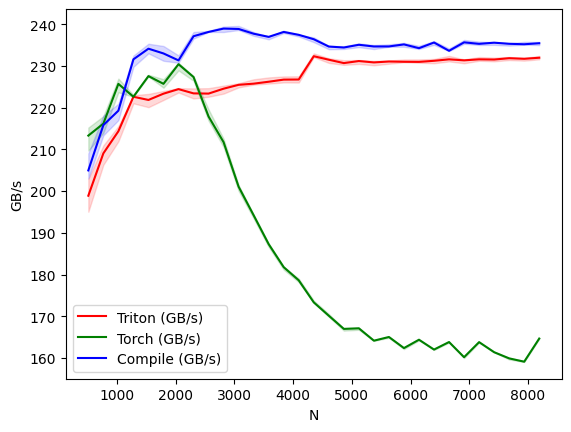

<Figure size 640x480 with 0 Axes>

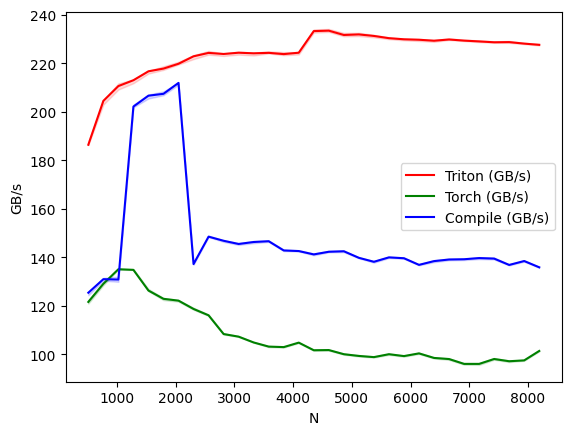

<Figure size 640x480 with 0 Axes>

In [8]:
#@title run check and benchmark functions
# make a folder to store result
import os
os.makedirs("results", exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
if(device == 'cpu'):
    raise RuntimeError("Get a GPU to run the code.")

for N in [256*i for i in range(2, 33)]:
  check_triton_vs_torch(1234, N, device)
fwd_benchmark.run(show_plots = True, save_path="results")
bwd_benchmark.run(show_plots = True, save_path="results")